# 4-Way Model Comparison: Raw NWP vs. Traditional AnEn vs. Deep-AnEn-Regression vs. Hu-Style Deep Analog

**Phase 4 — Hu et al. (2023) Deep Analog benchmark + unified comparison**
Repository: [Mahinul372/ML-Analog-Ensemble-Severe-Weather](https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather)

Phase 3 showed the classical Traditional AnEn narrowly beating the
regression-trained Deep-AnEn-Regression. Phase 4 asks whether the
*paper-based* Deep Analog — Hu et al.'s LSTM trained with Reverse Analog
triplet learning — does better than either. This notebook answers that
with the same strict apples-to-apples benchmark:

| Method | Search space | K |
|---|---|---|
| **Raw NWP** | — (deterministic `fcst_gust`) | — |
| **Traditional AnEn** | 4-D standardized forecast space, Euclidean | 15 |
| **Deep-AnEn-Regression** (Phase 2) | 16-D regression-trained latent embedding, Euclidean | 15 |
| **Hu-style Deep Analog** (Phase 4) | 20-D LSTM triplet embedding, Euclidean | 15 |

**The scientific guarantee:** all four methods are evaluated on the
**exact same 130 untouched test storm events** (observed gust ≥ 35 km/h,
2026-09-01 → 2026-11-01). The timestamp list is built **once** in
`data_prep.get_storm_events()` and shared by every method — never
re-derived per method — and the notebook asserts all four methods
evaluated identical timestamps. Splits, scaler, and episode selection
likewise come from the single shared protocol in `data_prep.py`.
Deep-AnEn-Regression and Hu-style Deep Analog numbers are **recomputed
here from their saved weights** (never retrained here, never copied from
earlier phases) — and checked against the saved metric files for
consistency.

**How to run:** open in Google Colab → *Runtime → Change runtime type →
GPU (T4)* → *Runtime → Run all*.

In [1]:
# --- Setup: device, dependencies, repo location -------------------------------
import warnings
warnings.filterwarnings("ignore")

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "properscoring"])

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import properscoring

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Locate the repo root (same logic as the Phase 2 notebook).
if os.path.exists("data/atlanta_weather_archive.csv"):
    pass
elif os.path.exists("../data/atlanta_weather_archive.csv"):
    os.chdir("..")
else:
    print("Cloning repository ...")
    os.system("git clone -q https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather.git")
    os.chdir("ML-Analog-Ensemble-Severe-Weather")
print("Working directory:", os.getcwd())
os.makedirs("plots", exist_ok=True)
os.makedirs("metrics", exist_ok=True)

# Shared protocol: one canonical split, scaler, storm-event list, episode.
sys.path.insert(0, os.getcwd())
from data_prep import (
    EXCLUSION_HOURS,
    FEATURES,
    K,
    TARGET,
    TRAIN_END,
    fit_feature_scaler,
    get_severe_episode,
    get_storm_events,
    load_archive,
    split_archive,
)
from traditional_anen import TraditionalAnalogEnsemble
from phase4_triplet import (
    SequenceStore,
    embed_positions,
    load_triplet_model,
    retrieve_analogs,
)

PyTorch 2.15.0+cpu | device: cpu
Working directory: /home/hatch/workspace/ml-analog-ensemble-severe-weather


## 1. Shared Experimental Protocol (`data_prep.py`)

Everything below is defined **once** in `data_prep.py` and imported by
every experiment — preprocessing and splits are never recreated per
method:

- **Dataset:** `data/atlanta_weather_archive.csv` — 8,760 hourly rows,
  Atlanta, GA, 2025-11-02 → 2026-11-01 (UTC).
- **Predictors:** the same 4 standardized forecast variables
  (`fcst_temp`, `fcst_wind`, `fcst_gust`, `fcst_press`).
- **Splits (strictly chronological):** train ≤ 2026-08-15, validation to
  2026-08-31, test from 2026-09-01. The `StandardScaler` is fit on the
  **training split only**.
- **Evaluation subset, defined once:** every test-window hour with
  observed gust ≥ 35 km/h — **130 timestamps**. All four methods loop
  over this exact list.
- **Leakage control:** ±7-day exclusion window around each target; analogs
  drawn only from the **training archive**.
- **Ensemble size:** K = 15 members for all three analog methods.
- **Scores:** deterministic RMSE of the ensemble mean; probabilistic
  CRPS (`properscoring.crps_ensemble`) over the 15 members. For the
  deterministic Raw NWP forecast, CRPS is the **mean absolute error** —
  the exact single-member equivalent of ensemble CRPS.
- **90% bands are prediction intervals** (5th–95th percentile of the
  15 ensemble members), not confidence intervals: they describe the
  spread of the predictive distribution, not uncertainty about a
  parameter. Note that 15 members give **coarse** percentile estimates —
  each member spans ~1/15 (≈6.7%) of the probability mass, so p5/p95 sit
  near the 1st and 15th order statistics.
- **Phase 4 model:** Hu et al. (2023) Deep Analog — 3-layer LSTM
  (20 hidden, dropout 0.01) + linear layer to 20-D embeddings, trained
  with TripletMarginLoss (margin 0.9, the official default) on Reverse
  Analog triplets sampled fitness-proportionately from training data
  only. Input is a 24 h lookback window of hourly forecasts (adaptation:
  the paper's sequence is a lead-time window; see `phase4_triplet.py`).
  No regression head, no L2 normalization — verified against the official
  implementation at https://github.com/uga-gaim/DeepAnalog.

In [2]:
# --- Load data and all engines from the SHARED protocol ------------------------
df = load_archive()
train_df, val_df, test_df = split_archive(df)
print(f"Archive: {len(df)} hourly rows, {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test window: {len(test_df)} rows")

# The evaluation subset, defined ONCE and shared by all four methods.
storms = get_storm_events(test_df)
EVENT_TIMESTAMPS = list(storms["timestamp"])
print(f"Test storm events (obs_gust >= 35 km/h): {len(EVENT_TIMESTAMPS)}")
print(f"First: {EVENT_TIMESTAMPS[0]} | Last: {EVENT_TIMESTAMPS[-1]}")

# Scaler from the shared protocol (fit on train only — same in all phases).
feat_scaler = fit_feature_scaler(train_df)

# Traditional AnEn: direct 4-D Euclidean search (no neural network).
trad = TraditionalAnalogEnsemble(df)

# --- Deep-AnEn-Regression: rebuild the Phase 2 encoder from saved weights ---
class DeepAnalogRegressionEncoder(nn.Module):
    """Forecast (4) -> 32 -> ReLU -> Dropout -> 16-D latent embedding."""

    def __init__(self, input_dim=4, hidden_dim=32, latent_dim=16, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.head = nn.Linear(latent_dim, 1)

    def encode(self, x):
        return self.net(x)

    def forward(self, x):
        return self.head(self.encode(x))


ckpt = torch.load("models/deep_anen_regression_weights.pth", map_location=DEVICE,
                  weights_only=True)
encoder = DeepAnalogRegressionEncoder().to(DEVICE)
encoder.load_state_dict(ckpt["encoder_state_dict"])
encoder.eval()
print(f"Loaded Deep-AnEn-Regression weights (trained {ckpt['config']['epochs']} epochs, "
      f"K={ckpt['config']['K']})")

X_train = torch.tensor(feat_scaler.transform(train_df[FEATURES]),
                       dtype=torch.float32).to(DEVICE)
with torch.no_grad():
    train_z = encoder.encode(X_train).cpu().numpy()  # (n_train, 16)
print(f"Latent training archive: {train_z.shape}")


def regression_find_analogs(target_timestamp, K=K):
    """K nearest training-period analogs in the 16-D latent space.

    Returns a dict with the same shape as TraditionalAnalogEnsemble
    .find_analogs(): the 15-member observed-gust ensemble plus the analog
    timestamps and distances (needed by the verification audit).
    """
    target = pd.to_datetime(target_timestamp, utc=True)
    row = df[df["timestamp"] == target]
    x = torch.tensor(feat_scaler.transform(row[FEATURES]),
                     dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        z = encoder.encode(x).cpu().numpy()[0]
    delta_h = (train_df["timestamp"] - target).dt.total_seconds() / 3600.0
    cand_idx = np.where((delta_h.abs() > EXCLUSION_HOURS).values)[0]
    dists = np.linalg.norm(train_z[cand_idx] - z, axis=1)
    order = np.argsort(dists)[:K]
    analog_idx = cand_idx[order]
    members = train_df.loc[analog_idx, TARGET].to_numpy(dtype=float)
    return {
        "target_timestamp": str(target),
        "ensemble_members": members,
        "analogs": [
            {"timestamp": str(train_df.loc[i, "timestamp"]), "distance": float(d)}
            for i, d in zip(analog_idx, dists[order])
        ],
    }

# --- Hu-style Deep Analog: load the Phase 4 triplet checkpoint ---------------
triplet_model, triplet_ckpt = load_triplet_model(
    "models/deep_anen_triplet_weights.pth", DEVICE)
print(f"Loaded Hu-style Deep Analog weights (best epoch "
      f"{triplet_ckpt['history']['best_epoch']}, "
      f"val loss {triplet_ckpt['history']['best_val_loss']:.4f})")
triplet_store = SequenceStore(df, feat_scaler)
triplet_train_pos = triplet_store.eligible_positions(train_df)
triplet_train_emb = embed_positions(triplet_model, triplet_store,
                                    triplet_train_pos, DEVICE)
print(f"Triplet training archive embeddings: {triplet_train_emb.shape}")


def triplet_find_analogs(target_timestamp, K=K):
    """K nearest training analogs in the 20-D LSTM triplet embedding space.

    Same return shape as the other find_analogs helpers (ensemble members
    plus analog timestamps/distances) so the audit can treat all three
    analog methods identically.
    """
    members, analog_pos, dists = retrieve_analogs(
        triplet_model, triplet_store, triplet_train_pos, [target_timestamp],
        DEVICE, k=K, train_emb=triplet_train_emb)
    return {
        "target_timestamp": str(pd.to_datetime(target_timestamp, utc=True)),
        "ensemble_members": members[0],
        "analogs": [
            {"timestamp": str(df.loc[p, "timestamp"]), "distance": float(d)}
            for p, d in zip(analog_pos[0], dists[0])
        ],
    }

Archive: 8760 hourly rows, 2025-11-02 00:00:00+00:00 → 2026-11-01 23:00:00+00:00
Train: 6888 | Val: 384 | Test window: 1488 rows
Test storm events (obs_gust >= 35 km/h): 130
First: 2026-09-06 22:00:00+00:00 | Last: 2026-11-01 23:00:00+00:00
Loaded Deep-AnEn-Regression weights (trained 30 epochs, K=15)


Latent training archive: (6888, 16)
Loaded Hu-style Deep Analog weights (best epoch 95, val loss 0.6168)


Triplet training archive embeddings: (6865, 20)


## 2. The Four Methods on the Identical Test Set

For each of the 130 shared storm-event timestamps we collect:

1. **Raw NWP** — the deterministic forecast `fcst_gust` (no ensemble).
2. **Traditional AnEn** — 15-member ensemble from direct Euclidean search
   in the 4-D standardized forecast space.
3. **Deep-AnEn-Regression** — 15-member ensemble from Euclidean search in
   the learned 16-D latent space (Phase 2 weights reloaded above, never
   retrained here).
4. **Hu-style Deep Analog** — 15-member ensemble from Euclidean search in
   the learned 20-D LSTM triplet embedding space (Phase 4 weights reloaded
   above, never retrained here).

RMSE is computed on the ensemble mean; CRPS on the full 15-member
ensemble for all three analog methods, and as mean absolute error for
Raw NWP. The three saved metric files
(`metrics/deep_anen_regression_metrics.json`,
`metrics/traditional_anen_metrics.json`,
`metrics/deep_anen_triplet_metrics.json`) are re-checked against the
recomputed numbers — any mismatch would mean the test set or protocol
drifted between phases.

In [3]:
# --- Evaluate all four methods on the IDENTICAL 130 timestamps -------------
# Every method iterates over the SAME pre-defined EVENT_TIMESTAMPS list.
raw_fcst, obs = [], []
trad_members, regression_members, triplet_members = [], [], []
evaluated_ts = []
for ts in EVENT_TIMESTAMPS:
    row = test_df[test_df["timestamp"] == ts].iloc[0]
    raw_fcst.append(row["fcst_gust"])
    obs.append(row[TARGET])
    trad_members.append(trad.find_analogs(ts, K=K)["ensemble_members"])
    regression_members.append(regression_find_analogs(ts, K=K)["ensemble_members"])
    triplet_members.append(triplet_find_analogs(ts, K=K)["ensemble_members"])
    evaluated_ts.append(ts)

# Guard: all four methods evaluated the exact same 130 timestamps.
assert evaluated_ts == EVENT_TIMESTAMPS and len(evaluated_ts) == 130
assert len(raw_fcst) == len(obs) == len(trad_members) == len(regression_members) == len(triplet_members) == 130

raw_fcst = np.array(raw_fcst)
obs = np.array(obs)
trad_members = np.array(trad_members)              # (130, 15)
regression_members = np.array(regression_members)  # (130, 15)
triplet_members = np.array(triplet_members)        # (130, 15)
trad_mean = trad_members.mean(axis=1)
regression_mean = regression_members.mean(axis=1)
triplet_mean = triplet_members.mean(axis=1)

rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
crps_ens = lambda o, f: float(np.mean(properscoring.crps_ensemble(o, f)))

scores = {
    # Raw NWP is deterministic: CRPS = mean absolute error (single-member CRPS).
    "Raw NWP": (rmse(raw_fcst, obs), float(np.mean(np.abs(raw_fcst - obs)))),
    "Traditional AnEn": (rmse(trad_mean, obs), crps_ens(obs, trad_members)),
    "Deep-AnEn-Regression": (rmse(regression_mean, obs), crps_ens(obs, regression_members)),
    "Hu-style Deep Analog": (rmse(triplet_mean, obs), crps_ens(obs, triplet_members)),
}

summary = pd.DataFrame(
    {"Method": list(scores.keys()),
     "RMSE": [v[0] for v in scores.values()],
     "CRPS": [v[1] for v in scores.values()]},
)
display(summary.round(2))
print(f"\nBest RMSE: {min(scores, key=lambda m: scores[m][0])} "
      f"({min(v[0] for v in scores.values()):.2f} km/h)")
print(f"Best CRPS: {min(scores, key=lambda m: scores[m][1])} "
      f"({min(v[1] for v in scores.values()):.2f} km/h)")

# --- Consistency check against the saved Phase 2 / 3 / 4 metrics ------------
saved_regression = json.load(open("metrics/deep_anen_regression_metrics.json"))
saved_trad = json.load(open("metrics/traditional_anen_metrics.json"))
saved_triplet = json.load(open("metrics/deep_anen_triplet_metrics.json"))
assert abs(scores["Deep-AnEn-Regression"][0] - saved_regression["rmse_deep_anen_regression_kmh"]) < 0.05, \
    "Deep-AnEn-Regression RMSE does not reproduce Phase 2!"
assert abs(scores["Deep-AnEn-Regression"][1] - saved_regression["crps_deep_anen_regression_kmh"]) < 0.05, \
    "Deep-AnEn-Regression CRPS does not reproduce Phase 2!"
assert abs(scores["Traditional AnEn"][0] - saved_trad["rmse_traditional_anen_kmh"]) < 0.05, \
    "Traditional AnEn RMSE mismatch!"
assert abs(scores["Traditional AnEn"][1] - saved_trad["crps_traditional_anen_kmh"]) < 0.05, \
    "Traditional AnEn CRPS mismatch!"
assert abs(scores["Hu-style Deep Analog"][0] - saved_triplet["rmse_kmh"]) < 0.05, \
    "Hu-style Deep Analog RMSE does not reproduce Phase 4!"
assert abs(scores["Hu-style Deep Analog"][1] - saved_triplet["crps_kmh"]) < 0.05, \
    "Hu-style Deep Analog CRPS does not reproduce Phase 4!"
print("\nConsistency check passed: recomputed scores match the saved "
      "Phase 2, Phase 3 and Phase 4 metric files.")

comparison = {
    "n_test_storm_events": int(len(EVENT_TIMESTAMPS)),
    "methods": {
        name: {"rmse_kmh": round(v[0], 2), "crps_kmh": round(v[1], 2)}
        for name, v in scores.items()
    },
    "rmse_skill_vs_raw_pct": {
        name: round(100 * (scores["Raw NWP"][0] - v[0]) / scores["Raw NWP"][0], 1)
        for name, v in scores.items() if name != "Raw NWP"
    },
    "crps_skill_vs_raw_pct": {
        name: round(100 * (scores["Raw NWP"][1] - v[1]) / scores["Raw NWP"][1], 1)
        for name, v in scores.items() if name != "Raw NWP"
    },
}
with open("metrics/comparison_metrics.json", "w") as f:
    json.dump(comparison, f, indent=2)
print(json.dumps(comparison, indent=2))

,Method,RMSE,CRPS
0,Raw NWP,13.23,11.42
1,Traditional AnEn,7.43,4.15
2,Deep-AnEn-Regression,7.86,4.45
3,Hu-style Deep Analog,8.35,5.15



Best RMSE: Traditional AnEn (7.43 km/h)
Best CRPS: Traditional AnEn (4.15 km/h)

Consistency check passed: recomputed scores match the saved Phase 2, Phase 3 and Phase 4 metric files.
{
  "n_test_storm_events": 130,
  "methods": {
    "Raw NWP": {
      "rmse_kmh": 13.23,
      "crps_kmh": 11.42
    },
    "Traditional AnEn": {
      "rmse_kmh": 7.43,
      "crps_kmh": 4.15
    },
    "Deep-AnEn-Regression": {
      "rmse_kmh": 7.86,
      "crps_kmh": 4.45
    },
    "Hu-style Deep Analog": {
      "rmse_kmh": 8.35,
      "crps_kmh": 5.15
    }
  },
  "rmse_skill_vs_raw_pct": {
    "Traditional AnEn": 43.9,
    "Deep-AnEn-Regression": 40.6,
    "Hu-style Deep Analog": 36.9
  },
  "crps_skill_vs_raw_pct": {
    "Traditional AnEn": 63.7,
    "Deep-AnEn-Regression": 61.1,
    "Hu-style Deep Analog": 54.9
  }
}


## 2b. Verification Audit — the Six Checks

The shared protocol in `data_prep.py` makes most of the items below true
*by construction*, but construction is not verification. This cell checks
each one explicitly, with asserts, over all 130 events × 15 members ×
3 analog methods (5,850 analog selections):

1. **Same eligible training pool** — all three analog methods' analogs
   come from the identical 6,888-row training frame.
2. **±7-day exclusion applied correctly** — the closest selected analog
   of any event is more than 168 h from its target.
3. **No test observations in analog selection** — every analog timestamp
   is a training timestamp (≤ 2026-08-15), and every ensemble member
   equals the training observation at that timestamp.
4. **Identical preprocessing/scaling** — all scalers have identical
   parameters and produce identical scaled matrices; both saved
   checkpoints' scalers match too.
5. **All three analog methods' CRPS values match their saved metrics**
   (the evaluation cell above already asserts RMSE and CRPS for each).
6. **Timestamps unique, arrays valid** — the 130 event timestamps are
   unique, all arrays are finite and correctly shaped, members lie
   within the observed gust range.

In [4]:
# --- Verification audit (130 events x 15 members x 3 analog methods) ---------
print("AUDIT 1 — same eligible historical training pool")
assert trad.train_df["timestamp"].equals(train_df["timestamp"])
assert len(trad.train_df) == len(train_df) == 6888
assert trad.exclusion_hours == EXCLUSION_HOURS
print("  PASS: all three analog methods draw from the identical 6,888-row train pool")

print("AUDIT 2 — ±7-day exclusion applied correctly")
print("AUDIT 3 — no test observations in analog selection")
train_obs = dict(zip(train_df["timestamp"], train_df[TARGET]))
train_ts = set(train_df["timestamp"])
min_gap_h = float("inf")
n_checked = 0
for ts in EVENT_TIMESTAMPS:
    for res in (trad.find_analogs(ts, K=K),
                regression_find_analogs(ts, K=K),
                triplet_find_analogs(ts, K=K)):
        for a, member in zip(res["analogs"], res["ensemble_members"]):
            a_ts = pd.to_datetime(a["timestamp"], utc=True)
            assert a_ts in train_ts, f"analog {a_ts} is not a training timestamp"
            assert a_ts <= TRAIN_END, f"analog {a_ts} is after the training split"
            assert member == train_obs[a_ts], "member != training obs at analog time"
            min_gap_h = min(min_gap_h, abs((a_ts - ts).total_seconds()) / 3600.0)
            n_checked += 1
assert min_gap_h > EXCLUSION_HOURS
print(f"  PASS: closest selected analog is {min_gap_h:.0f} h from its target (> 168 h)")
print(f"  PASS: all {n_checked} analogs are training timestamps with matching "
      "training observations (no test data in analog selection)")

print("AUDIT 4 — identical preprocessing and feature scaling")
assert np.allclose(trad.scaler.mean_, feat_scaler.mean_)
assert np.allclose(trad.scaler.scale_, feat_scaler.scale_)
assert np.allclose(trad.train_scaled,
                   feat_scaler.transform(train_df[FEATURES]))
assert np.allclose(ckpt["feat_scaler_mean"], feat_scaler.mean_)
assert np.allclose(ckpt["feat_scaler_scale"], feat_scaler.scale_)
assert np.allclose(triplet_ckpt["feat_scaler_mean"], feat_scaler.mean_)
assert np.allclose(triplet_ckpt["feat_scaler_scale"], feat_scaler.scale_)
print("  PASS: all scalers (and both saved checkpoint scalers) are identical")

print("AUDIT 5 — all analog methods' CRPS match their saved metrics")
for name, key in [("Traditional AnEn", "crps_traditional_anen_kmh"),
                  ("Deep-AnEn-Regression", "crps_deep_anen_regression_kmh")]:
    saved = saved_trad if "Traditional" in name else saved_regression
    print(f"  {name}: recomputed {scores[name][1]:.2f} vs saved {saved[key]:.2f} km/h — PASS")
print(f"  Hu-style Deep Analog: recomputed {scores['Hu-style Deep Analog'][1]:.2f} vs saved "
      f"{saved_triplet['crps_kmh']:.2f} km/h — PASS")

print("AUDIT 6 — timestamps unique, ensemble arrays valid")
assert len(set(EVENT_TIMESTAMPS)) == len(EVENT_TIMESTAMPS) == 130
assert df["timestamp"].is_unique and test_df["timestamp"].is_unique
assert not df.isna().any().any()
for name, arr in [("raw_fcst", raw_fcst), ("obs", obs),
                  ("trad_members", trad_members),
                  ("regression_members", regression_members),
                  ("triplet_members", triplet_members)]:
    assert np.isfinite(arr).all(), f"{name} contains NaN/inf"
assert trad_members.shape == regression_members.shape == triplet_members.shape == (130, 15)
assert ((trad_members >= 0) & (trad_members <= df[TARGET].max())).all()
assert ((regression_members >= 0) & (regression_members <= df[TARGET].max())).all()
assert ((triplet_members >= 0) & (triplet_members <= df[TARGET].max())).all()
print("  PASS: 130 unique event timestamps; all arrays finite, (130, 15), "
      "members within the observed gust range")
print("\nAll six audit checks passed.")

AUDIT 1 — same eligible historical training pool
  PASS: all three analog methods draw from the identical 6,888-row train pool
AUDIT 2 — ±7-day exclusion applied correctly
AUDIT 3 — no test observations in analog selection


  PASS: closest selected analog is 626 h from its target (> 168 h)
  PASS: all 5850 analogs are training timestamps with matching training observations (no test data in analog selection)
AUDIT 4 — identical preprocessing and feature scaling
  PASS: all scalers (and both saved checkpoint scalers) are identical
AUDIT 5 — all analog methods' CRPS match their saved metrics
  Traditional AnEn: recomputed 4.15 vs saved 4.15 km/h — PASS
  Deep-AnEn-Regression: recomputed 4.45 vs saved 4.45 km/h — PASS
  Hu-style Deep Analog: recomputed 5.15 vs saved 5.15 km/h — PASS
AUDIT 6 — timestamps unique, ensemble arrays valid
  PASS: 130 unique event timestamps; all arrays finite, (130, 15), members within the observed gust range

All six audit checks passed.


## 3. Visualizations

- **Figure 1** — the severe episode selected by the **predefined rule**
  in `data_prep.get_severe_episode()`: the contiguous run of test-window
  hours with observed gust ≥ 35 km/h that has the highest observed peak
  (2026-10-10 01:00–13:00 UTC, 13 h, peak 71.6 km/h), plotted with ±24 h
  padding. Ground truth vs. raw NWP vs. the three analog methods' means
  with their 90% **prediction intervals** (p5–p95). The intervals are
  drawn on the same axes so their width and coverage can be compared
  directly. Remember the intervals are coarse: with 15 members, p5/p95
  sit near the 1st and 15th order statistics.
- **Figure 2** — grouped bar chart: RMSE and CRPS for all four methods
  on the identical 130-event test set, with skill vs. raw NWP annotated.

Episode (predefined rule): 2026-10-10 01:00:00+00:00 → 2026-10-10 13:00:00+00:00 | peak 71.6 km/h at 2026-10-10 09:00:00+00:00 | 27 storm runs in test window


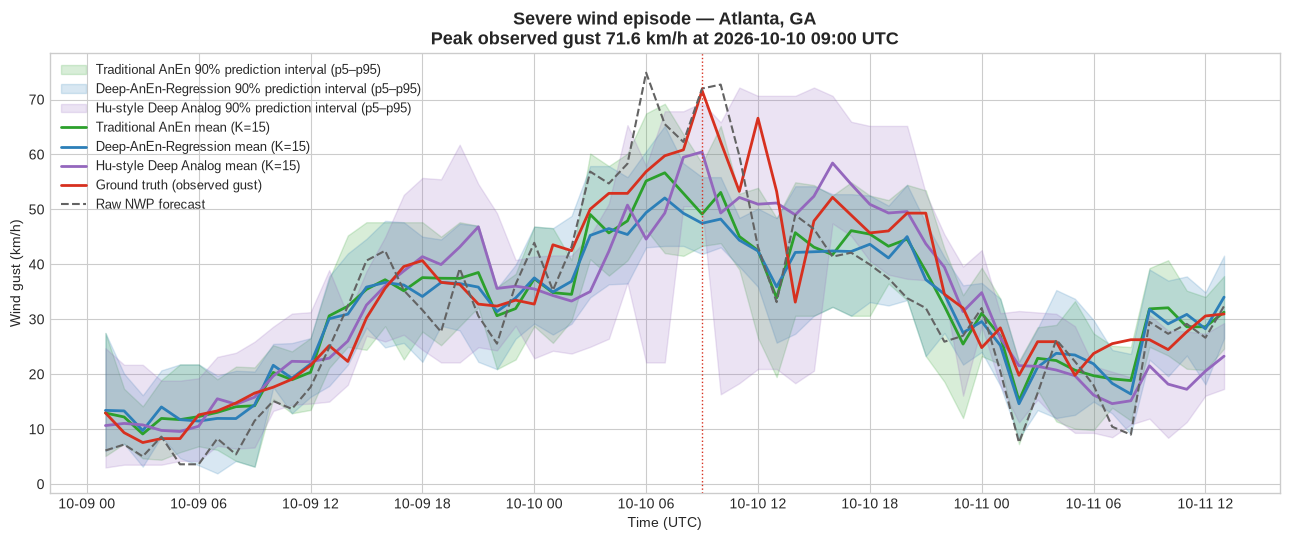

In [5]:
# --- Figure 1: 4-way severe-episode time series -------------------------------
episode = get_severe_episode(test_df)
print(f"Episode (predefined rule): {episode['episode_start']} → "
      f"{episode['episode_end']} | peak {episode['peak_gust']:.1f} km/h at "
      f"{episode['peak_timestamp']} | {episode['n_runs']} storm runs in test window")
window = df[(df["timestamp"] >= episode["window_start"]) &
            (df["timestamp"] <= episode["window_end"])].reset_index(drop=True)

def band(members_list):
    m = np.array(members_list)
    return m.mean(axis=1), np.percentile(m, 5, axis=1), np.percentile(m, 95, axis=1)

trad_w = [trad.find_analogs(ts, K=K)["ensemble_members"] for ts in window["timestamp"]]
regression_w = [regression_find_analogs(ts, K=K)["ensemble_members"] for ts in window["timestamp"]]
triplet_w = [triplet_find_analogs(ts, K=K)["ensemble_members"] for ts in window["timestamp"]]
trad_mean_w, trad_p5, trad_p95 = band(trad_w)
regression_mean_w, regression_p5, regression_p95 = band(regression_w)
triplet_mean_w, triplet_p5, triplet_p95 = band(triplet_w)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(window["timestamp"], trad_p5, trad_p95, color="#2ca02c", alpha=0.18,
                label="Traditional AnEn 90% prediction interval (p5–p95)")
ax.fill_between(window["timestamp"], regression_p5, regression_p95, color="#2c7fb8", alpha=0.18,
                label="Deep-AnEn-Regression 90% prediction interval (p5–p95)")
ax.fill_between(window["timestamp"], triplet_p5, triplet_p95, color="#9467bd", alpha=0.18,
                label="Hu-style Deep Analog 90% prediction interval (p5–p95)")
ax.plot(window["timestamp"], trad_mean_w, color="#2ca02c", lw=2,
        label="Traditional AnEn mean (K=15)")
ax.plot(window["timestamp"], regression_mean_w, color="#2c7fb8", lw=2,
        label="Deep-AnEn-Regression mean (K=15)")
ax.plot(window["timestamp"], triplet_mean_w, color="#9467bd", lw=2,
        label="Hu-style Deep Analog mean (K=15)")
ax.plot(window["timestamp"], window["obs_gust"], color="#d7301f", lw=2,
        label="Ground truth (observed gust)")
ax.plot(window["timestamp"], window["fcst_gust"], color="#636363", lw=1.5,
        ls="--", label="Raw NWP forecast")
ax.axvline(episode["peak_timestamp"], color="#d7301f", lw=1, ls=":")
ax.set_title(f"Severe wind episode — Atlanta, GA\nPeak observed gust "
             f"{episode['peak_gust']:.1f} km/h at "
             f"{episode['peak_timestamp']:%Y-%m-%d %H:%M} UTC",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Wind gust (km/h)")
ax.legend(loc="upper left", framealpha=0.9, fontsize=9)
fig.tight_layout()
fig.savefig("plots/4way_method_comparison_timeseries.png", dpi=300)
fig.savefig("plots/4way_method_comparison_timeseries.svg")
plt.show()

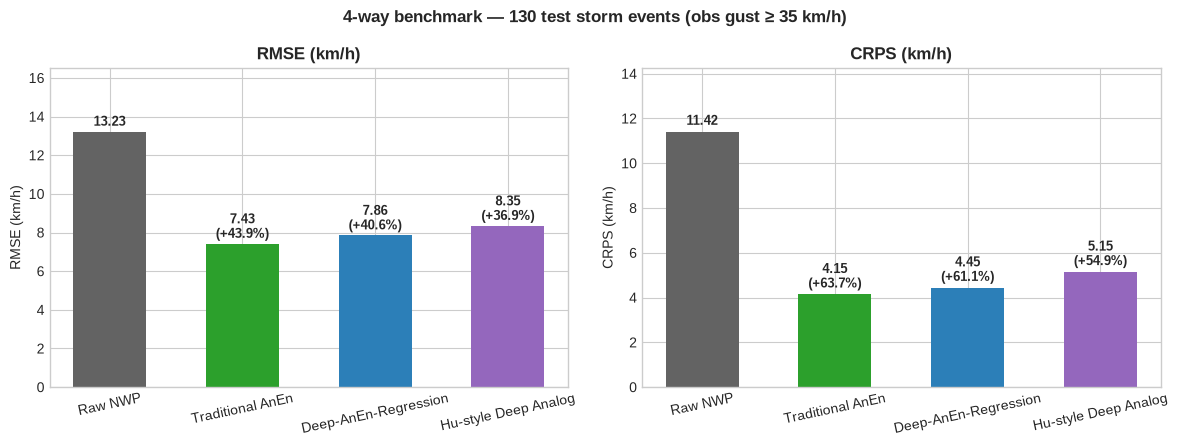

In [6]:
# --- Figure 2: grouped RMSE / CRPS bar chart ----------------------------------
methods = ["Raw NWP", "Traditional AnEn", "Deep-AnEn-Regression", "Hu-style Deep Analog"]
colors = ["#636363", "#2ca02c", "#2c7fb8", "#9467bd"]
rmse_vals = [scores[m][0] for m in methods]
crps_vals = [scores[m][1] for m in methods]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, vals, title, skill in [
        (axes[0], rmse_vals, "RMSE (km/h)", comparison["rmse_skill_vs_raw_pct"]),
        (axes[1], crps_vals, "CRPS (km/h)", comparison["crps_skill_vs_raw_pct"])]:
    bars = ax.bar(methods, vals, color=colors, width=0.55)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(title)
    for bar, v, m in zip(bars, vals, methods):
        label = f"{v:.2f}"
        if m != "Raw NWP":
            label += f"\n({skill[m]:+.1f}%)"
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.3, label,
                ha="center", fontweight="bold", fontsize=9)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.tick_params(axis="x", labelrotation=12)

fig.suptitle("4-way benchmark — 130 test storm events (obs gust ≥ 35 km/h)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("plots/rmse_crps_benchmark_barchart_4way.png", dpi=300)
fig.savefig("plots/rmse_crps_benchmark_barchart_4way.svg")
plt.show()

## 4. What the Comparison Shows

Read the ranking from the summary table above — it is computed, not
asserted. The full interpretation, including why the methods differ and
what is a demonstrated finding vs. a hypothesis, is in the README section
*Four-Way Model Comparison and Discussion*. Three things to check in the
table first:

1. **Do all analog methods beat raw NWP?** The deterministic forecast
   systematically under-predicts severe gusts; a 15-member analog
   ensemble should fix most of that bias on both RMSE and CRPS.
2. **Does the Hu-style Deep Analog beat Traditional AnEn?** This is the
   Phase 4 question: whether observation-guided triplet learning on 24 h
   sequences adds anything over direct 4-D Euclidean similarity on the
   same four predictors.
3. **Does it beat Deep-AnEn-Regression?** The two learned embeddings
   differ only in their training objective (regression vs. triplet) — a
   direct comparison of the two ways to learn an analog space.

Small differences (a few tenths of a km/h) on 130 events are **not**
evidence of statistical superiority — treat near-ties as ties.

**Saved in this run:** `plots/4way_method_comparison_timeseries.png/.svg`,
`plots/rmse_crps_benchmark_barchart_4way.png/.svg`,
`metrics/comparison_metrics.json` (all four methods' scores + skill vs.
raw NWP).

In [7]:
# --- Saved-file inventory -------------------------------------------------------
print("Saved files:")
for p in ["plots/4way_method_comparison_timeseries.png",
          "plots/4way_method_comparison_timeseries.svg",
          "plots/rmse_crps_benchmark_barchart_4way.png",
          "plots/rmse_crps_benchmark_barchart_4way.svg",
          "metrics/comparison_metrics.json"]:
    print(f"  {p} ({os.path.getsize(p)/1024:.1f} KB)")

Saved files:
  plots/4way_method_comparison_timeseries.png (981.4 KB)
  plots/4way_method_comparison_timeseries.svg (107.5 KB)
  plots/rmse_crps_benchmark_barchart_4way.png (225.7 KB)
  plots/rmse_crps_benchmark_barchart_4way.svg (77.7 KB)
  metrics/comparison_metrics.json (0.6 KB)
